# EDA — Customer Churn

## 1. Contexto del proyecto

El proyecto busca analizar el abandono de clientes (`Churn`) y detectar qué características aparecen asociadas al churn para, posteriormente, construir un modelo de predicción.

El dataset utilizado es el **IBM Telco Customer Churn Dataset**, reinterpretado dentro del proyecto como un caso de negocio SaaS B2B.

El objetivo de este notebook es realizar un EDA sencillo y comprensible, como el que realizaría un analista de datos junior: revisar la calidad de los datos, entender el target y comparar las principales variables con `Churn`.

## 2. Importar librerías

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

## 3. Cargar el dataset

In [2]:
DATA_PATH = '../data/raw/telco_customer_churn.csv'

df = pd.read_csv(DATA_PATH)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


El archivo original se mantiene sin modificar. A partir de aquí trabajaremos con una copia para realizar la limpieza necesaria.

In [3]:
df_clean = df.copy()
df_clean.shape

(7043, 21)

## 4. Revisión inicial

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Observación inicial

El dataset contiene alrededor de 7.000 clientes y combina variables numéricas, categóricas y la variable objetivo `Churn`.

## 5. Valores nulos y valores vacíos

In [6]:
df_clean.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
# Comprobamos cadenas vacías en las columnas de texto
df_clean.select_dtypes(include='object').apply(lambda x: x.str.strip().eq('').sum()).sort_values(ascending=False).head(10)

C:\Users\alebo\AppData\Local\Temp\ipykernel_19320\502746544.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_clean.select_dtypes(include='object').apply(lambda x: x.str.strip().eq('').sum()).sort_values(ascending=False).head(10)


TotalCharges       11
customerID          0
gender              0
Partner             0
PhoneService        0
Dependents          0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
MultipleLines       0
dtype: int64

`TotalCharges` aparece como texto y contiene cadenas vacías. Como representa un importe, debe convertirse a numérico. Las cadenas vacías pasarán a `NaN`.

Los registros afectados tienen `tenure = 0`, por lo que no se imputan automáticamente como `0`: primero se documenta el problema y se conserva el valor como faltante.

In [8]:
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')

df_clean[['TotalCharges', 'MonthlyCharges', 'tenure']].isnull().sum()

TotalCharges      11
MonthlyCharges     0
tenure             0
dtype: int64

## 6. Duplicados

In [9]:
print('Filas duplicadas:', df_clean.duplicated().sum())
print('customerID duplicados:', df_clean['customerID'].duplicated().sum())

Filas duplicadas: 0
customerID duplicados: 0


No se eliminan registros porque no se han detectado duplicados. `customerID` se conserva para identificar clientes, pero no se utilizará como variable predictora en el futuro modelo.

## 7. Comprobar valores sospechosos

In [10]:
df_clean[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].agg(['min', 'max'])

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
min,0,0,18.25,18.8
max,1,72,118.75,8684.8


In [11]:
print('tenure negativos:', (df_clean['tenure'] < 0).sum())
print('MonthlyCharges negativos:', (df_clean['MonthlyCharges'] < 0).sum())
print('TotalCharges negativos:', (df_clean['TotalCharges'] < 0).sum())
print('SeniorCitizen distintos:', sorted(df_clean['SeniorCitizen'].dropna().unique()))

tenure negativos: 0
MonthlyCharges negativos: 0
TotalCharges negativos: 0
SeniorCitizen distintos: [np.int64(0), np.int64(1)]


No se observan valores negativos en las variables monetarias ni en `tenure`, y `SeniorCitizen` utiliza las categorías esperadas `0` y `1`.

## 8. Distribución del target: `Churn`

In [12]:
df_clean['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [13]:
df_clean['Churn'].value_counts(normalize=True).mul(100).round(2)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

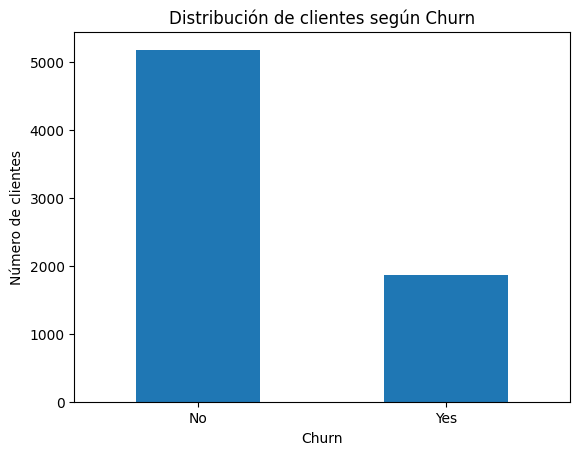

In [14]:
df_clean['Churn'].value_counts().plot(kind='bar')
plt.title('Distribución de clientes según Churn')
plt.xlabel('Churn')
plt.ylabel('Número de clientes')
plt.xticks(rotation=0)
plt.show()

**Insight:** En los datos analizados, `Churn = Yes` representa el **26,54%** de los clientes y `Churn = No` el **73,46%**. La clase `Yes` es minoritaria, pero tiene un tamaño suficiente para analizar sus características y será importante tener en cuenta este desbalance en la fase de modelado.

Este porcentaje describe la composición del dataset; no debe interpretarse como una tasa mensual sin información temporal adicional.

## 9. Variables numéricas vs Churn

In [15]:
df_clean.groupby('Churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].median().round(2)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.43,1683.60
Yes,10.0,79.65,703.55


### `tenure`

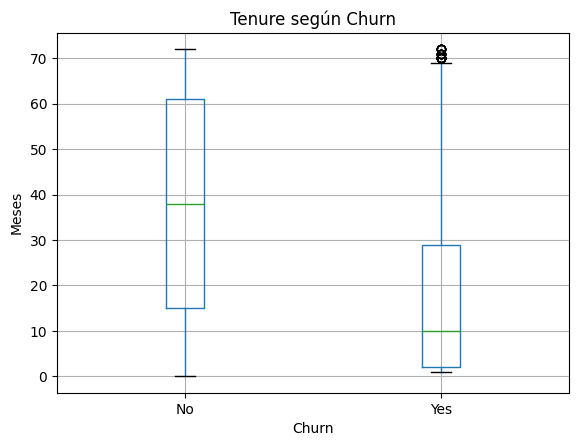

In [16]:
df_clean.boxplot(column='tenure', by='Churn')
plt.title('Tenure según Churn')
plt.suptitle('')
plt.xlabel('Churn')
plt.ylabel('Meses')
plt.show()

**Insight:** la mediana de `tenure` es de aproximadamente **10 meses** en clientes con churn y **38 meses** en clientes que permanecen. En este dataset, el churn aparece asociado con una menor antigüedad.

Esto es una asociación descriptiva: no permite afirmar que una menor antigüedad sea la causa del churn.

### `MonthlyCharges`

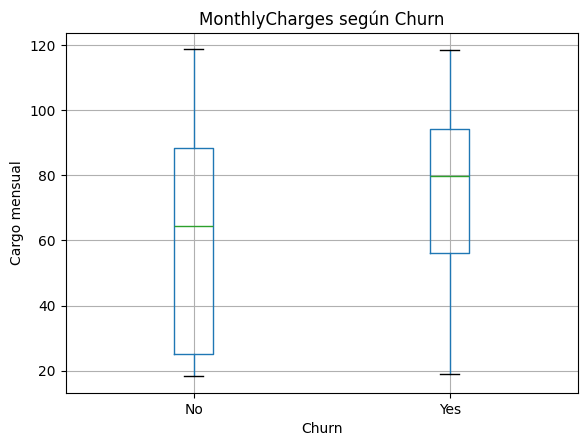

In [17]:
df_clean.boxplot(column='MonthlyCharges', by='Churn')
plt.title('MonthlyCharges según Churn')
plt.suptitle('')
plt.xlabel('Churn')
plt.ylabel('Cargo mensual')
plt.show()

**Insight:** la mediana de `MonthlyCharges` es aproximadamente **79,65** para `Churn = Yes` y **64,43** para `Churn = No`. Los clientes con churn presentan cargos mensuales centrales superiores en esta muestra.

Será necesario analizar posteriormente qué servicios y tipos de contrato están relacionados con estos cargos.

### `TotalCharges`

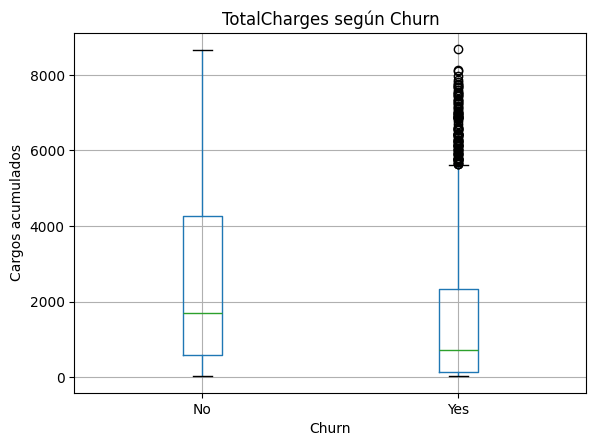

In [18]:
df_clean.boxplot(column='TotalCharges', by='Churn')
plt.title('TotalCharges según Churn')
plt.suptitle('')
plt.xlabel('Churn')
plt.ylabel('Cargos acumulados')
plt.show()

**Insight:** la mediana de `TotalCharges` es aproximadamente **703,55** en `Churn = Yes` y **1.683,60** en `Churn = No`.

Esta diferencia debe interpretarse con cuidado porque `TotalCharges` depende mucho del tiempo que el cliente lleva en la empresa (`tenure`). Por ello, no se considera por sí sola una señal independiente de churn.

## 10. Variables categóricas vs Churn

Para las variables categóricas utilizaremos el **churn rate dentro de cada categoría**. Esto permite comparar categorías con tamaños diferentes.

In [19]:
contract_churn = pd.crosstab(df_clean['Contract'], df_clean['Churn'], normalize='index') * 100
contract_churn.round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


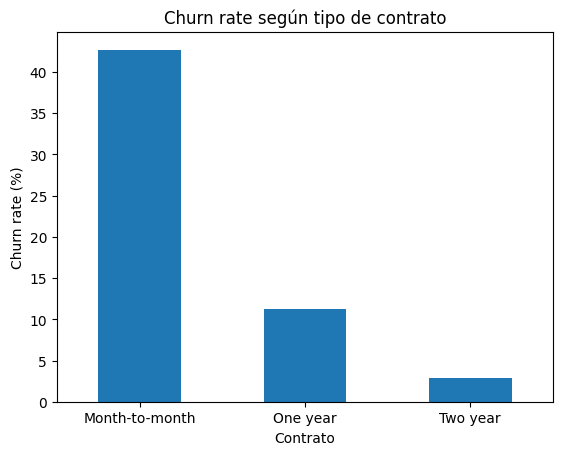

In [20]:
contract_churn['Yes'].sort_values(ascending=False).plot(kind='bar')
plt.title('Churn rate según tipo de contrato')
plt.xlabel('Contrato')
plt.ylabel('Churn rate (%)')
plt.xticks(rotation=0)
plt.show()

**Insight:** `Month-to-month` presenta un churn rate del **42,71%**, frente al **11,27%** de `One year` y el **2,83%** de `Two year`. Es una de las diferencias descriptivas más claras del EDA. No implica causalidad.

In [21]:
payment_churn = pd.crosstab(df_clean['PaymentMethod'], df_clean['Churn'], normalize='index') * 100
payment_churn.round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


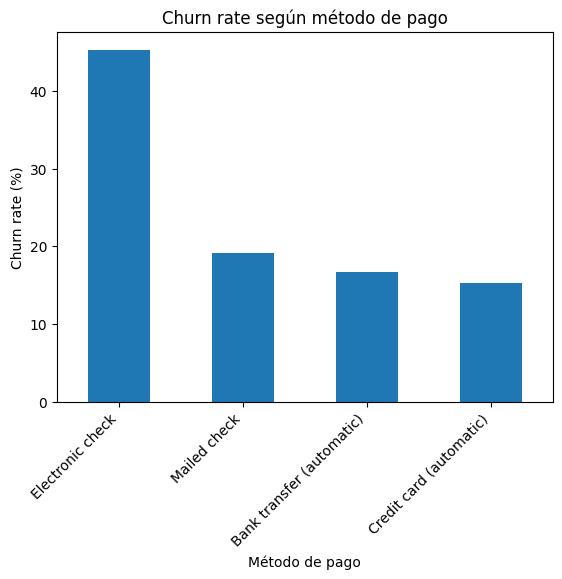

In [22]:
payment_churn['Yes'].sort_values(ascending=False).plot(kind='bar')
plt.title('Churn rate según método de pago')
plt.xlabel('Método de pago')
plt.ylabel('Churn rate (%)')
plt.xticks(rotation=45, ha='right')
plt.show()

**Insight:** `Electronic check` presenta un churn rate del **45,29%**, superior al de los demás métodos observados. Conviene investigar si esta diferencia está relacionada con el tipo de contrato, el perfil del cliente u otras variables.

In [23]:
internet_churn = pd.crosstab(df_clean['InternetService'], df_clean['Churn'], normalize='index') * 100
internet_churn.round(2)

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


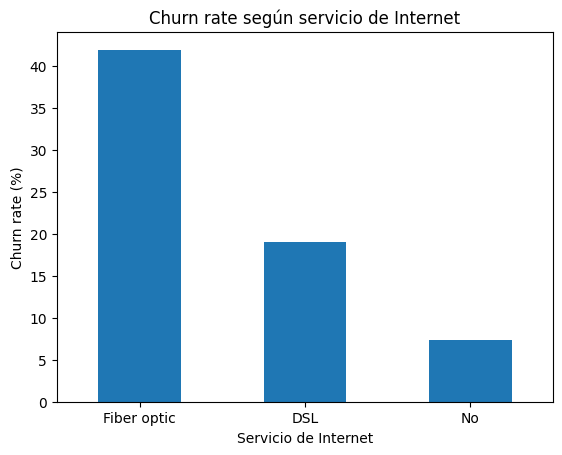

In [24]:
internet_churn['Yes'].sort_values(ascending=False).plot(kind='bar')
plt.title('Churn rate según servicio de Internet')
plt.xlabel('Servicio de Internet')
plt.ylabel('Churn rate (%)')
plt.xticks(rotation=0)
plt.show()

**Insight:** `Fiber optic` presenta un churn rate del **41,89%**, frente al **18,96%** de `DSL` y el **7,40%** de clientes sin Internet. La diferencia es descriptiva y debe estudiarse junto con otras variables.

## 11. Resumen del EDA

### Principales hallazgos

1. El dataset contiene **7.043 clientes** y la proporción de registros con `Churn = Yes` es del **26,54%**.
2. Los clientes con churn presentan una mediana de `tenure` claramente inferior (**10 frente a 38 meses**).
3. Los clientes con churn presentan una mediana de `MonthlyCharges` superior (**79,65 frente a 64,43**).
4. `TotalCharges` es inferior en el grupo con churn, pero esta diferencia está muy relacionada con `tenure`.
5. `Month-to-month` presenta un churn rate del **42,71%**, frente al **2,83%** de `Two year`.
6. `Electronic check` presenta un churn rate del **45,29%**.
7. `Fiber optic` presenta un churn rate del **41,89%**.

### Perfil descriptivo observado

En esta muestra, el churn aparece especialmente concentrado entre clientes con menor antigüedad y se observan diferencias de churn según contrato, método de pago y servicio de Internet.

### Limitaciones

- El dataset no contiene una evolución temporal de cada cliente, por lo que no podemos estudiar correctamente cuándo se produce el churn mes a mes.
- Las diferencias encontradas son asociaciones descriptivas y no demuestran causalidad.
- `TotalCharges` está relacionada con `tenure`, por lo que debe interpretarse con cautela.
- Este EDA no determina todavía qué variables serán las más importantes para el modelo; eso se estudiará en la fase de modelado.

### Siguiente paso

Utilizar estos hallazgos para preparar las variables para el modelo de churn y comprobar si los patrones observados se mantienen al analizar varias variables conjuntamente.

## 12. Guardar dataset limpio

In [25]:
df_clean.to_parquet('../data/processed/cleaned.parquet', index=False)

print('Dataset limpio guardado correctamente.')

Dataset limpio guardado correctamente.
